# Python examples in lecture 5
* This file is a jupyter notebook. To run it you can download it from the DLE and run it on your own machine.
* Or you can run it on google collab <https://colab.research.google.com> via your google account. This may be slower than running on your own machine

This notebook shows how to run basic SQL commands from python

##  First example of SQL command

We will look at the simplefolks.sqlite database file.

Download the SQLite file from **SimpleFolks for Simple SQL**
http://2016.padjo.org/files/data/starterpack/simplefolks.sqlite The file simplefolks.sqlite needs to be in the same directory as this notebook.

You can read more about the dataset at http://2016.padjo.org/tutorials/sql-simplefolks-select-from/

The above database has the following tables:
homes, inmates, people, pets and politicians.

The politicians table has columns:
bioguide_id , position, state, party, first_name,
last_name , birth_year , service_start, service_end.

**SELECT * FROM politicians**

* **\*** means everything
* **politicians** is the table name

The database in the file simplefolks.sqlite

In [3]:
import sqlite3

connection = sqlite3.connect("simplefolks.sqlite")
cursor = connection.cursor()

cursor.execute("SELECT * FROM politicians ") 
result = cursor.fetchall() 
#for r in result:
#    print(r)
print(result[0])

('B01', 'Rep', 'CA', 'Union', 'Billy', 'Bush', 1959, 1980, 2010)


##  Second SQL example
* The type command in python can help unpack the results

In [2]:
import sqlite3
connection = sqlite3.connect("simplefolks.sqlite")
cursor = connection.cursor()
cursor.execute("select first_name, last_name, birth_year from politicians")
result = cursor.fetchall() 
for r in result:
    print(r)


('Billy', 'Bush', 1959)
('Don', 'Dunk', 1980)
('Louis', 'Libby', 1945)
('Hilary', 'Lintoncay', 1965)
('Daniel', 'Noogen', 1977)
('Manuel', 'Roastancowski', 1920)
('John', 'Smith', 1933)
('Janet', 'Smith', 1954)
('Janet', 'Smith', 1974)


##  Third SQL example
* The type command ican help unpack the results

In [3]:
import sqlite3

connection = sqlite3.connect("simplefolks.sqlite")
cursor = connection.cursor()
cursor.execute("select first_name, last_name, birth_year from politicians where birth_year > 1970")
res = cursor.fetchone() 
result = cursor.fetchall() 
for r in result:
    print(r)

('Daniel', 'Noogen', 1977)
('Janet', 'Smith', 1974)


## An important note

* The python script and the database file (simplefolks.sqlite) have to be in the **same directory** for this script to work.

* If the python script doesn't find the database file, it will exit and print the confusing error message that it can't find the table.

* Sometimes it will also create a version of the database file with zero length, which will then continue to fail.





##  Format of the sqlite file

* Typically there are no applications on PC/mac to read sqlite file.
* Online tools can help debug https://inloop.github.io/sqlite-viewer/


##  PEP 249 – Python Database API Specification
* Why is the cursor required ?
* PEP Python Enhancement Proposals  (https://peps.python.org/pep-0000/)

<blockquote>
This API has been defined to encourage similarity between the 
Python modules that are used to access databases. By doing this, we hope to achieve a consistency leading to 
more easily understood modules, code that is generally more portable across databases, 
and a broader reach of database connectivity from Python.
</blockquote>

Database PEP  https://peps.python.org/pep-0249/

## MySQL example
From https://www.w3schools.com/python/python_mysql_select.asp  (It will not run)

In [4]:
import mysql.connector
mydb = mysql.connector.connect(
  host="localhost",
  user="yourusername",
  password="yourpassword",
  database="mydatabase"
)
mycursor = mydb.cursor()
mycursor.execute("SELECT * FROM customers")
myresult = mycursor.fetchall()
for x in myresult:
  print(x)

ModuleNotFoundError: No module named 'mysql'

## Another example

<blockquote>
    The management of a company have noticed that the
productivity of the firm is reduced, because a
number of employees are off sick because of the flu.
The CEO suggests that it would be interesting to see 
if it was cost effective for the company to pay for 
the flu jab for all employees.
</blockquote>

The human resources department has two tables stored
in a SQLite database in the file: **HR_info.db**. 
This file is available from the DLE.




##  Flu jab example continued

The database (**HR_info.db**) contains two tables <br>

TABLE **HR_info** with the columns:
* **staff_number** INTEGER PRIMARY KEY
* **salary** INTEGER
* **age** INTEGER

TABLE **flu_info** with the columns:
* **flu_treatment** INTEGER PRIMARY KEY
* **staff_number** INTEGER 
* **days_off** INTEGER



##  Reading in all the information from one table

The file HR_info.db is on the DLE.

In [5]:
import sqlite3
connection = sqlite3.connect("HR_info.db")
cursor = connection.cursor()
cursor.execute("SELECT * FROM HR_info  ") 
result = cursor.fetchall() 
print("Staff_number Salary Age") 
for r in result:
    print(r[0], r[1], r[2])

Staff_number Salary Age
0 30000 64
1 35000 37
2 35000 56
3 25000 30
4 35000 42
5 30000 51
6 30000 46
7 20000 55
8 20000 21
9 25000 57
10 30000 46
11 35000 30
12 35000 70
13 20000 27
14 30000 51
15 30000 48
16 30000 21
17 25000 58
18 30000 61
19 25000 63
20 30000 70
21 25000 55
22 30000 38
23 25000 44
24 20000 64
25 35000 24
26 25000 35
27 20000 21
28 30000 45
29 25000 29


##  A more complex query

Find employee over 50 who earn more than 30,000 pounds

In [4]:
import sqlite3
connection = sqlite3.connect("HR_info.db")
cursor = connection.cursor()
cursor.execute("SELECT * FROM HR_info where age > 50 and salary > 30000 ") 
result = cursor.fetchall() 
print("Staff_number Salary Age") 
for r in result:
    print(r[0], r[1], r[2])

Staff_number Salary Age
2 35000 56
12 35000 70


## Pulling the data from the table and plotting it
* We want to make a plot of salary versus age 
* This is a basic data science task

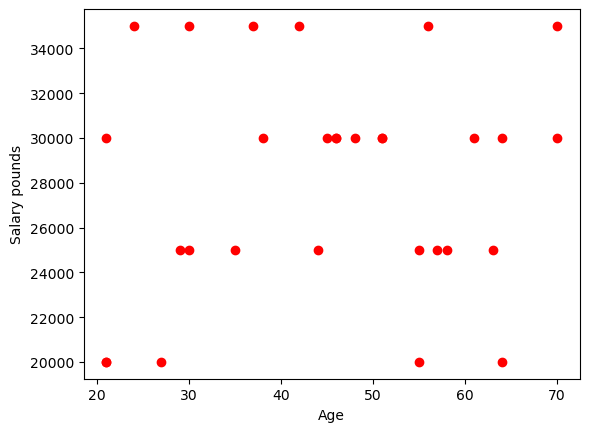

In [8]:
import sqlite3
import matplotlib.pyplot as plt
connection = sqlite3.connect("HR_info.db")
cursor = connection.cursor()
cursor.execute("SELECT * FROM HR_info") 
result = cursor.fetchall() 
age = [] 
salary = [] 
for r in result:
#   print(r[0], r[1], r[2])
    salary.append(r[1])
    age.append(r[2])
plt.plot(age,salary, "ro")
plt.xlabel('Age')
plt.ylabel(r'Salary pounds')
#rint(age)
#print(salary)
plt.show()


##  Extracting information from SQLlite file


* What if we are given the file **HR_info.db** but no information about the tables.

* Can we find the table names and the names of the columns?

* Is the datafile self describing?




## Useful utility

There is a command line interface to sqlite
(https://www.sqlite.org/cli.html). This is typically installed
with Anaconda.


* **sqlite3.exe** on Windows

* **sqlite3** program on my Mac.


This program is useful for looking at small files and debugging.


On my Linux machine using the command:  sqlite3 HR_info.db

<pre>
sqlite3 HR_info.db
sqlite> .databases
main: ./HR_info.db
sqlite> .schema
CREATE TABLE HR_info (
staff_number INTEGER PRIMARY KEY,
salary INTEGER,
age INTEGER);
CREATE TABLE flu_info (
flu_treatment INTEGER PRIMARY KEY,
staff_number INTEGER,
days_off INTEGER);

</pre>

## Finding the tables in HR_info.db

The file **HR_info.db** is on the DLE.


In [8]:
import sqlite3
connection = sqlite3.connect("HR_info.db")
cursor = connection.cursor()
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';") 
result = cursor.fetchall() 
for r in result:
    print(r)


('HR_info',)
('flu_info',)


## Finding the column names in HR_info.db

* The file HR_info.db is on the DLE.
* The example below finds the column names of the table HR_info
* PRAGMA  is specific to SQLite, so it is not portable to other databases (https://www.sqlite.org/pragma.html.)


In [9]:
import sqlite3
connection = sqlite3.connect("HR_info.db")
cursor = connection.cursor()
cursor.execute("PRAGMA table_info(HR_info);") 
result = cursor.fetchall() 
for r in result:
    print(r)

(0, 'staff_number', 'INTEGER', 0, None, 1)
(1, 'salary', 'INTEGER', 0, None, 0)
(2, 'age', 'INTEGER', 0, None, 0)


##  Checking whether the database file exists
* One issue is that the sqlite database connect will not produce an error, if that file does not exist.
* Even worse the the API will create an empty database file 

In principle, it would be better to use exceptions (https://www.w3schools.com/python/python_try_except.asp)
to check whether the file exists,
before you try too read it

In [10]:
! rm new_info.db
# this example will not catch the error if the file new_info.db  does not exist
import sqlite3
try:
  connection = sqlite3.connect("new_info.db")
except sqlite3.Error as err:
  print("Error reading database file")

print("Start to work with the database")

rm: cannot remove 'new_info.db': No such file or directory
Start to work with the database


##  Testing whether a file exists
* The os module (os - Operating System ) can check whether a file exists
* See  https://www.digitalocean.com/community/tutorials/python-os-module for more information

In [11]:
# Code to test whether a file exists
import os

file_name = "HGR_info.db"
if os.path.isfile(file_name) :
     print(file_name , " exists")
else:
     print(file_name , " NOT found")


HGR_info.db  NOT found


##  Checking whether a file exists
* By using special syntax Uniform Resource Identifier URI the open of the database can be 
* https://www.sqlite.org/uri.html

See the following for more infoormation
*  https://stackoverflow.com/questions/57828286/how-to-make-sqlite3-connect-fail-if-the-db-file-does-not-exist

In [12]:
# see information 
import sqlite3
database_file = "FHR_info.db"
try:
    # The open of the database is now readonly "ro"
    connection = sqlite3.connect("file:" + database_file  + "?mode=ro", uri=True)
except sqlite3.Error as err:
  print("Error reading the file " , database_file)



Error reading the file  FHR_info.db


In [13]:
#! rm GHR_info.db


## Sakila example

In [4]:
import sqlite3

connection = sqlite3.connect("akila.db")
cursor = connection.cursor()
# This is the SQL xcommand
cursor.execute("SELECT * FROM actor") 
result = cursor.fetchall() 
for r in result:
    print(r)


OperationalError: no such table: actor